# AI, Data Science and Software Development Employment

## Project objective
This project explores US employment and wages in occupations related
to AI, Data Science and Software Development using May 2023 BLS data.

It compares employment levels, salaries and geographical differences,
and uses additional years to investigate employment trends.

In [ ]:
%pip install pandas openpyxl matplotlib seaborn

## Loading and inspecting the dataset

The dataset contains US employment and wage estimates for May 2023.
I will inspect its columns, data types and sample rows before selecting
occupations related to AI, Data Science and Software Development.

In [2]:
import pandas as pd

file_path = "/Users/juma/Desktop/DataVisComms/ai-employment-analysis/ai-employment-analysis/oesm23all/all_data_M_2023.xlsx"

df = pd.read_excel(file_path)

df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Rows: 413327
Columns: 32

Column names:
['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']


In [5]:
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413327 entries, 0 to 413326
Data columns (total 32 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   AREA          413327 non-null  int64 
 1   AREA_TITLE    413327 non-null  object
 2   AREA_TYPE     413327 non-null  int64 
 3   PRIM_STATE    413327 non-null  object
 4   NAICS         413327 non-null  object
 5   NAICS_TITLE   413327 non-null  object
 6   I_GROUP       413327 non-null  object
 7   OWN_CODE      413327 non-null  int64 
 8   OCC_CODE      413327 non-null  object
 9   OCC_TITLE     413327 non-null  object
 10  O_GROUP       413327 non-null  object
 11  TOT_EMP       413327 non-null  object
 12  EMP_PRSE      413327 non-null  object
 13  JOBS_1000     235826 non-null  object
 14  LOC_QUOTIENT  235826 non-null  object
 15  PCT_TOTAL     170470 non-null  object
 16  PCT_RPT       170470 non-null  object
 17  H_MEAN        413327 non-null  object
 18  A_MEAN        413327 non

AREA                 0
AREA_TITLE           0
AREA_TYPE            0
PRIM_STATE           0
NAICS                0
NAICS_TITLE          0
I_GROUP              0
OWN_CODE             0
OCC_CODE             0
OCC_TITLE            0
O_GROUP              0
TOT_EMP              0
EMP_PRSE             0
JOBS_1000       177501
LOC_QUOTIENT    177501
PCT_TOTAL       242857
PCT_RPT         242857
H_MEAN               0
A_MEAN               0
MEAN_PRSE            0
H_PCT10              0
H_PCT25              0
H_MEDIAN             0
H_PCT75              0
H_PCT90              0
A_PCT10              0
A_PCT25              0
A_MEDIAN             0
A_PCT75              0
A_PCT90              0
ANNUAL          396830
HOURLY          412572
dtype: int64

## Selecting and preparing the data
I am going to work with Data Scientists, Software Developers, and
Computer and Information Research Scientists. These occupations
are pertinent to the study of data science, software development, and
AI research, but all people in these occupations do not deal with AI.

Regarding the national comparison, I will choose US cross-industry totals
from the dataset that come together with the combined ownership
category included in it. Thus, there is no confusion about comparing national
totals with state or individual industry totals.

"Employment" and "Annual Wage" columns will become numerical. Otherwise,
non-numerical observations will be marked as missing rather than zero.

In [ ]:
occupations = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information Research Scientists"
]

# Keep all geographical areas for later analysis.
selected = df[df["OCC_TITLE"].isin(occupations)].copy()

# Check the occupation codes and levels before continuing.
selected[["OCC_CODE", "OCC_TITLE", "O_GROUP"]].drop_duplicates()

In [7]:
numeric_columns = ["TOT_EMP", "A_MEAN", "A_MEDIAN"]

for column in numeric_columns:
    selected[column] = pd.to_numeric(
        selected[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

In [9]:
national = selected[
    (selected["AREA"] == 99)
    & (selected["NAICS"].astype(str).str.strip() == "000000")
    & (selected["OWN_CODE"] == 1235)
    & (selected["O_GROUP"] == "detailed")
].copy()

national = national[
    ["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN", "A_MEDIAN"]
]

display(national)

print("Number of selected rows:", len(national))
print("\nMissing values:")
print(national[numeric_columns].isna().sum())

,OCC_CODE,OCC_TITLE,TOT_EMP,A_MEAN,A_MEDIAN
138,15-1221,Computer and Information Research Scientists,35210.0,157160.0,145080.0
149,15-1252,Software Developers,1656880.0,138110.0,132270.0
165,15-2051,Data Scientists,192710.0,119040.0,108020.0


Number of selected rows: 3

Missing values:
TOT_EMP     0
A_MEAN      0
A_MEDIAN    0
dtype: int64


## Visualisation 1: Employment by occupation

### Objective
Compare national employment in three occupations related to AI,
data science and software development in May 2023.

### Why a horizontal bar chart?
Occupation is categorical and employment is numerical. Bar lengths
make the differences easy to compare. Horizontal bars also provide
space for long occupation names.

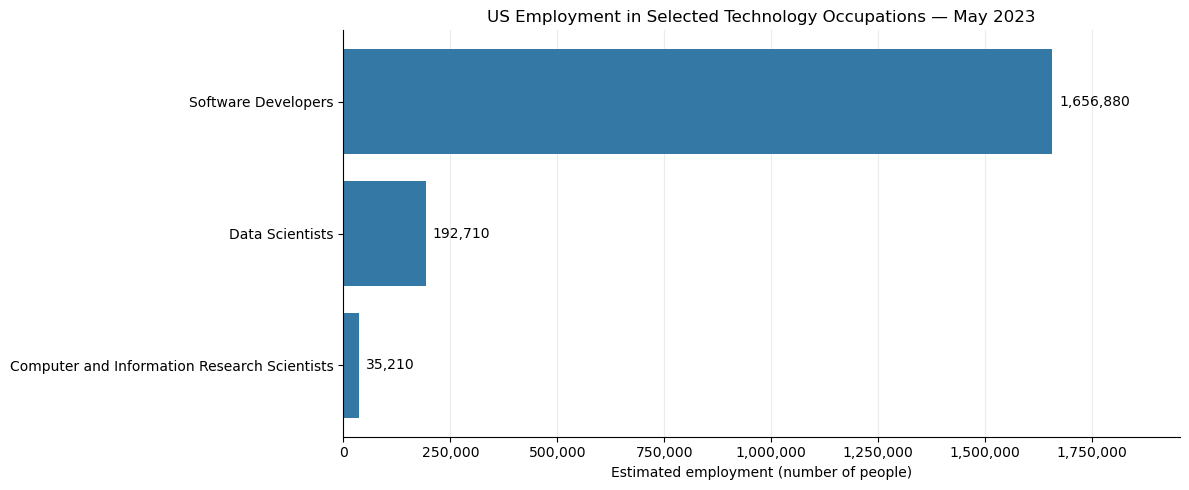

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


chart_data = national.sort_values("TOT_EMP", ascending=True)

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.barh(
    chart_data["OCC_TITLE"],
    chart_data["TOT_EMP"],
    color="#3478A5"
)


ax.bar_label(
    bars,
    labels=[f"{value:,.0f}" for value in chart_data["TOT_EMP"]],
    padding=5
)

ax.set_title("US Employment in Selected Technology Occupations — May 2023")
ax.set_xlabel("Estimated employment (number of people)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))


ax.set_xlim(0, chart_data["TOT_EMP"].max() * 1.18)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Results
The Software Developers occupation saw the largest employment, having 1,656,880 employed individuals,
as compared to 192,710 Data Scientists and 35,210 Computer and Information
Research Scientists.

The employment in software development is 8.6 times higher than the
employment in data science occupation, while the latter is about 47.1
times greater than the former.

It is evident that software development is the occupation which involves
the largest number of employees compared to the other two selected occupations.
The provided figures pertain to broader occupations associated with AI.

## Visualisation 2: Employment share by occupation

### Objective
Show the proportion of combined employment represented by each of
the three selected occupations in May 2023.

### Why a pie chart?
A pie chart shows parts of a whole. There are only three categories,
so it provides a clear overview of their relative shares.

The total represents only these three occupations, not all US
employment or all AI employment.

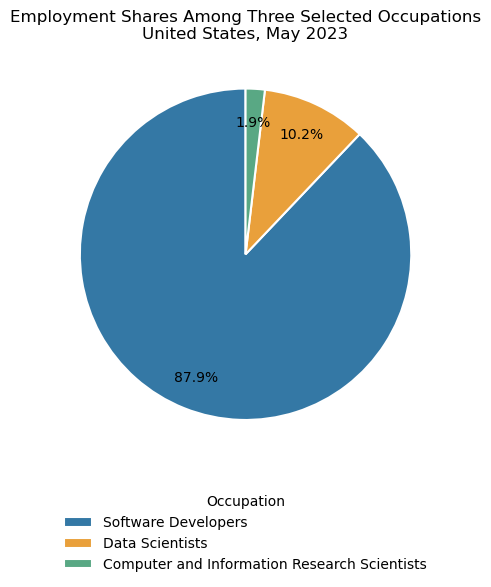

Combined employment: 1,884,800


In [11]:
pie_data = national.sort_values("TOT_EMP", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))

wedges, _, _ = ax.pie(
    pie_data["TOT_EMP"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#3478A5", "#E9A03B", "#59A884"],
    pctdistance=0.8,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)

ax.legend(
    wedges,
    pie_data["OCC_TITLE"],
    title="Occupation",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),
    frameon=False
)

ax.set_title(
    "Employment Shares Among Three Selected Occupations\n"
    "United States, May 2023"
)

plt.tight_layout()
plt.show()

print(f"Combined employment: {pie_data['TOT_EMP'].sum():,.0f}")

### Findings
The total number of employees from the above mentioned three occupations is 
1,884,800 people.

- Software developers occupied about 87.9%.
- Data scientists occupied about 10.2%.
- Computer and Information Research Scientists occupied about 1.9%.

The software developers occupy almost nine out of ten workers in the selected occupations.
The research scientists occupy the smallest part of the occupations, but the size of employment
does not tell the significance of the occupation to AI development.

This percentage only applies to the three selected occupations.

## Visualisation 3: Employment and mean annual wages

### Purpose
Examine the difference in size of employment and mean annual
salary between the three chosen occupations.

### Why is it a scatter plot?
This graph shows two numerical variables plotted on each axis: size of employment on
the horizontal axis and mean annual salary on the vertical axis.
One data point represents one occupation.

With just three points, this graph allows a description but not an inference regarding
correlation.

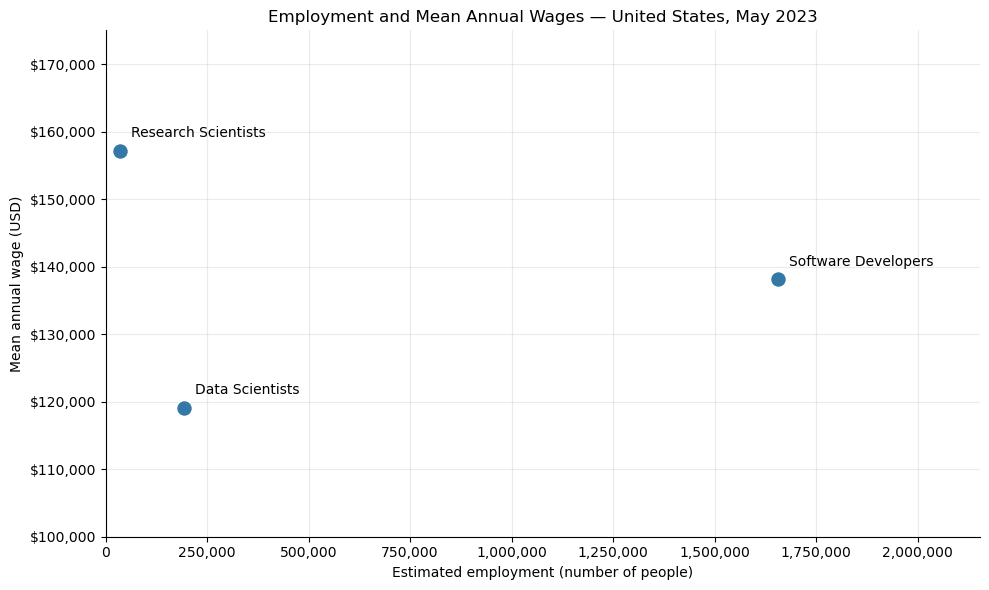

In [12]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

short_names = {
    "Computer and Information Research Scientists": "Research Scientists",
    "Software Developers": "Software Developers",
    "Data Scientists": "Data Scientists"
}

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    national["TOT_EMP"],
    national["A_MEAN"],
    s=130,
    color="#3478A5",
    edgecolor="white",
    linewidth=1,
    zorder=3
)

for _, row in national.iterrows():
    ax.annotate(
        short_names[row["OCC_TITLE"]],
        (row["TOT_EMP"], row["A_MEAN"]),
        xytext=(8, 10),
        textcoords="offset points",
        fontsize=10
    )

ax.set_title("Employment and Mean Annual Wages — United States, May 2023")
ax.set_xlabel("Estimated employment (number of people)")
ax.set_ylabel("Mean annual wage (USD)")

ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

# Leave room for labels.
ax.set_xlim(0, national["TOT_EMP"].max() * 1.3)
ax.set_ylim(100000, 175000)

ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Results
Computer and Information Research Scientists had the lowest total employment level (35,210), but the highest mean annual salary ($157,160).

Software Developers had the highest total employment level (1,656,880)
but only had a mean annual salary of $138,110.

Data Scientists had a total employment level of 192,710 and the
lowest mean annual salary of the three ($119,040).

The occupation having the largest number of workers did not have
the highest mean salary. The above three statements do not create any
relationship between employment levels and wages.

The above data refers to whole occupations, and not artificial intelligence workers.

## Visualization 4: Mean annual wages in selected states

### Objective
Comparison of mean annual wages in the three selected occupations in
California, Texas, New York, Washington, and Massachusetts.

They represent a suitable geographical comparison. They are an
illustrative selection and not the highest paying states ranked.

### Why use a heatmap?
This chart is used to compare numerical data with two categorical
variables; state and occupation. The colour scale denotes the variation
in wages while the cell values denote the actual data.

The wages are represented in US dollars thousand. The missing values
are left blank and are not considered to be zeros.

In [14]:
states_to_compare = [
    "California",
    "Texas",
    "New York",
    "Washington",
    "Massachusetts"
]

state_data = selected[
    selected["AREA_TITLE"].isin(states_to_compare)
    & (selected["NAICS"].astype(str).str.strip() == "000000")
    & (selected["OWN_CODE"] == 1235)
    & (selected["O_GROUP"] == "detailed")
].copy()

# Each state–occupation pair should appear only once.
assert not state_data.duplicated(
    ["AREA_TITLE", "OCC_CODE"]
).any(), "Duplicate state–occupation rows: check the filters."

wage_table = state_data.pivot(
    index="AREA_TITLE",
    columns="OCC_TITLE",
    values="A_MEAN"
).reindex(index=states_to_compare, columns=occupations)

display(wage_table)

OCC_TITLE,Data Scientists,Software Developers,Computer and Information Research Scientists
AREA_TITLE,,,
California,140490.0,173780.0,187420.0
Texas,109000.0,125890.0,139340.0
New York,134830.0,150020.0,158440.0
Washington,148730.0,159990.0,202910.0
Massachusetts,125100.0,146580.0,178820.0


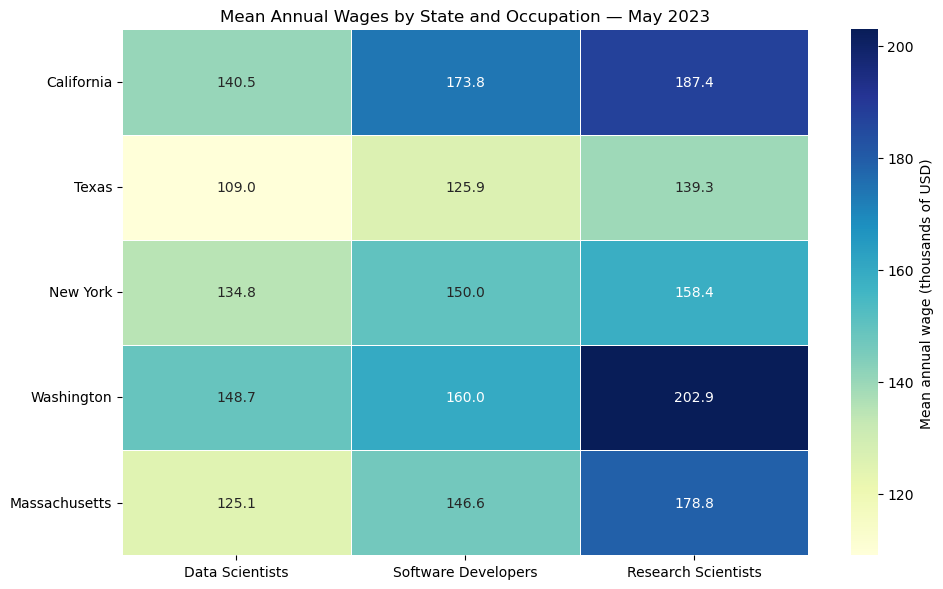

In [15]:
import seaborn as sns

# Convert wages to thousands of dollars for readable labels.
wage_thousands = wage_table.rename(columns=short_names) / 1000

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    wage_thousands,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    mask=wage_thousands.isna(),
    cbar_kws={"label": "Mean annual wage (thousands of USD)"},
    ax=ax
)

ax.set_title("Mean Annual Wages by State and Occupation — May 2023")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [16]:
for occupation in wage_table.columns:
    wages = wage_table[occupation].dropna()

    if wages.empty:
        print(f"{occupation}: no available wage estimates.\n")
        continue

    print(occupation)
    print(f"Highest among selected states: {wages.idxmax()} "
          f"(${wages.max():,.0f})")
    print(f"Lowest among selected states: {wages.idxmin()} "
          f"(${wages.min():,.0f})")
    print(f"Difference: ${wages.max() - wages.min():,.0f}\n")

Data Scientists
Highest among selected states: Washington ($148,730)
Lowest among selected states: Texas ($109,000)
Difference: $39,730

Software Developers
Highest among selected states: California ($173,780)
Lowest among selected states: Texas ($125,890)
Difference: $47,890

Computer and Information Research Scientists
Highest among selected states: Washington ($202,910)
Lowest among selected states: Texas ($139,340)
Difference: $63,570



### Results

Of the five chosen states, the mean annual wages were the highest for
Data Scientists ($148,730) and Computer and Information Research
Scientists ($202,910) in Washington, and the mean annual wage for
Software Developers ($173,780) was the highest in California.

Texas had the lowest mean annual wages in these three professions
considered in this comparison. The difference between the mean
annual wages of these professions in the state with the highest
and the state with the lowest value was:

- Data Scientists: $39,730.
- Software Developers: $47,890.
- Computer and Information Research Scientists: $63,570.

Research Scientists received the highest mean annual wage among the
three professions considered in all of the five chosen states.
Besides, they showed the biggest difference in wages in these
states.

These results reveal that the wages of the professions related to
AI differ depending on location. Nevertheless, the numbers were not
adjusted for living costs, and the chart does not provide any reasons
for such differences. The results can be applied only to the five
chosen states.

## Employment trends: 2023–2025

I will use the additional BLS “All data” datasets for May 2024
and May 2025 to explore employment changes in the three selected
occupations.

Before combining the years, I will check column names, occupation
codes and national coverage to ensure that equivalent records
are selected.

In [ ]:
from pathlib import Path
import os


project_folder = Path("/Users/juma/Desktop/DataVisComms/ai-employment-analysis/ai-employment-analysis")

if not (project_folder / "employment_analysis.ipynb").is_file():
    raise FileNotFoundError("This folder does not contain your notebook.")

os.chdir(project_folder)

print("Working folder:", Path.cwd())

for year in [2023, 2024, 2025]:
    path = Path(f"oesm{str(year)[-2:]}all/all_data_M_{year}.xlsx")
    print(year, "File found:", path.is_file())

Working folder: /Users/juma/Desktop/DataVisComms/ai-employment-analysis/ai-employment-analysis
2023 File found: True
2024 File found: True
2025 File found: True


In [21]:
import pandas as pd

for year in [2024, 2025]:
    path = Path(f"oesm{str(year)[-2:]}all/all_data_M_{year}.xlsx")

    with pd.ExcelFile(path) as workbook:
        print(f"\n--- {year} ---")
        print("Worksheets:", workbook.sheet_names)

        sample = pd.read_excel(workbook, sheet_name=0, nrows=5)
        print("Columns:", sample.columns.tolist())
        display(sample)


--- 2024 ---
Worksheets: ['All May 2024 data', 'Field Descriptions', 'UpdateTime', 'Filler']
Columns: ['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.80,37.89,60.44,29990,36730,49500,78810,125720,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,58.70,82.5,#,57010,79900,122090,171610,#,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,50.48,81.01,#,47510,68800,104990,168490,#,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.24,#,#,73710,126080,206420,#,#,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.24,#,#,73710,126080,206420,#,#,NaN,NaN



--- 2025 ---
Worksheets: ['All May 2025 data', 'Field Descriptions', 'UpdateTime', 'Filler']
Columns: ['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,24.51,38.71,61.81,31200,37590,50980,80520,128560,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,60.83,84.75,123.71,60130,82970,126520,176280,257310,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,52.17,82.85,134.48,50480,73260,108510,172330,279710,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,102.88,171.25,244.10,75700,129540,213990,356200,507730,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,102.88,171.25,244.10,75700,129540,213990,356200,507730,NaN,NaN


In [22]:
occupation_codes = ["15-1221", "15-1252", "15-2051"]

columns_needed = [
    "AREA", "NAICS", "OWN_CODE", "O_GROUP",
    "OCC_CODE", "OCC_TITLE", "TOT_EMP"
]

def load_national_employment(year):
    path = f"oesm{str(year)[-2:]}all/all_data_M_{year}.xlsx"

    data = pd.read_excel(
        path,
        sheet_name=f"All May {year} data",
        usecols=columns_needed,
        dtype={"OCC_CODE": str}
    )

    # Numeric conversion handles both 0 and "000000".
    cross_industry = pd.to_numeric(data["NAICS"], errors="coerce")

    result = data[
        (data["AREA"] == 99)
        & (cross_industry == 0)
        & (data["OWN_CODE"] == 1235)
        & (data["O_GROUP"].str.strip() == "detailed")
        & (data["OCC_CODE"].isin(occupation_codes))
    ][["OCC_CODE", "OCC_TITLE", "TOT_EMP"]].copy()

    result["TOT_EMP"] = pd.to_numeric(
        result["TOT_EMP"].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

    # Check that each occupation appears exactly once.
    assert len(result) == 3, f"{year}: expected three occupation rows."
    assert result["OCC_CODE"].is_unique, f"{year}: duplicate occupations."
    assert result["TOT_EMP"].notna().all(), f"{year}: missing employment."

    result["YEAR"] = year
    return result

In [23]:
national_2023 = national[
    ["OCC_CODE", "OCC_TITLE", "TOT_EMP"]
].copy()

national_2023["YEAR"] = 2023

national_2024 = load_national_employment(2024)
national_2025 = load_national_employment(2025)

employment_trends = pd.concat(
    [national_2023, national_2024, national_2025],
    ignore_index=True
)

display(employment_trends.sort_values(["OCC_CODE", "YEAR"]))

,OCC_CODE,OCC_TITLE,TOT_EMP,YEAR
0,15-1221,Computer and Information Research Scientists,35210.0,2023
3,15-1221,Computer and Information Research Scientists,38480.0,2024
6,15-1221,Computer and Information Research Scientists,37200.0,2025
1,15-1252,Software Developers,1656880.0,2023
4,15-1252,Software Developers,1654440.0,2024
7,15-1252,Software Developers,1687890.0,2025
2,15-2051,Data Scientists,192710.0,2023
5,15-2051,Data Scientists,233440.0,2024
8,15-2051,Data Scientists,262440.0,2025


In [24]:
employment_table = employment_trends.pivot(
    index="OCC_CODE",
    columns="YEAR",
    values="TOT_EMP"
)

occupation_names = national.set_index("OCC_CODE")["OCC_TITLE"]

summary = employment_table.copy()
summary.insert(0, "Occupation", occupation_names)

summary["Change 2023–2025"] = summary[2025] - summary[2023]
summary["Change (%)"] = (
    (summary[2025] / summary[2023] - 1) * 100
).round(1)

display(summary)

YEAR,Occupation,2023,2024,2025,Change 2023–2025,Change (%)
OCC_CODE,,,,,,
15-1221,Computer and Information Research Scientists,35210.0,38480.0,37200.0,1990.0,5.7
15-1252,Software Developers,1656880.0,1654440.0,1687890.0,31010.0,1.9
15-2051,Data Scientists,192710.0,233440.0,262440.0,69730.0,36.2


## Visualisation 5: Employment trends, 2023–2025

### Objective
Compare changes in national employment estimates for the three
selected occupations between May 2023 and May 2025.

### Why a line chart?
A line chart shows changes across ordered time points. Each line
represents one occupation, with markers showing the annual estimates.

Employment is indexed to 2023 = 100 because the occupations differ
greatly in size. This allows their relative changes to be compared.
For example, an index of 120 means employment was 20% above its
2023 estimate. The accompanying table provides actual employment totals.

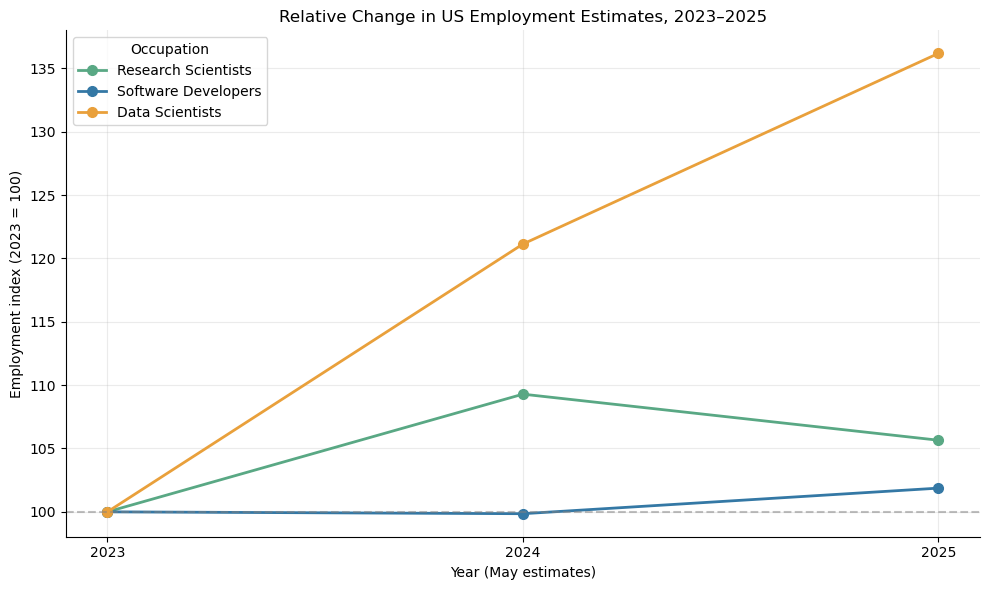

In [25]:
# Set each occupation's 2023 employment to an index of 100.
indexed_employment = employment_table.div(
    employment_table[2023], axis=0
) * 100

years = [2023, 2024, 2025]

colors = {
    "15-1221": "#59A884",
    "15-1252": "#3478A5",
    "15-2051": "#E9A03B"
}

fig, ax = plt.subplots(figsize=(10, 6))

for code in indexed_employment.index:
    name = occupation_names.loc[code]

    ax.plot(
        years,
        indexed_employment.loc[code, years],
        marker="o",
        linewidth=2,
        markersize=7,
        color=colors[code],
        label=short_names.get(name, name)
    )

ax.axhline(100, color="grey", linestyle="--", alpha=0.5)

ax.set_title("Relative Change in US Employment Estimates, 2023–2025")
ax.set_xlabel("Year (May estimates)")
ax.set_ylabel("Employment index (2023 = 100)")
ax.set_xticks(years)

ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title="Occupation")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Findings

The biggest percentage increase in employment occurred in the Data
Scientists category. Employment increased from 192,710 in 2023 to
262,440 in 2025 for a total increase of 69,730 or 36.2%.

Computer and Information Research Scientists grew by 5.7% in total
from 35,210 to 37,200. The category saw its peak employment of
38,480 in 2024 and subsequently decreased in 2025.

Software Developers remained the most common occupation in all the
three years. Employment decreased slightly in 2024 and then grew to
1,687,890 in 2025 for a total increase of 31,010 or 1.9%.

These findings show that employment in the data science occupation
grew faster than in the other selected occupations in the specified
period. Nonetheless, these occupations have some employment that has
nothing to do with AI.

### Limitations

This is a simple comparison of annual estimates of employment in
three years. This analysis does not prove the reasons behind changes
in employment or any statistically significant difference between the
numbers. Even occupation code match cannot ensure comparability of
the datasets due to survey methodology differences.

The indexed chart only shows relative changes but not the level of
employment.

## General conclusion

Software Developers had the greatest estimated number of employees of the
three chosen occupations in May 2023, amounting to 1,656,880 employees.
Computer and Information Research Scientists had the highest national
mean annual wage of $157,160.

Geographical wage differences were evident in the state analysis.
Among the five states selected, the highest mean wages were found in
Washington for Data Scientists and Research Scientists and California for
Software Developers.

For the time period of 2023-2025, the estimated number of Data
Scientists grew by 36.2%, while that of Research Scientists and Software
Developers grew by 5.7% and 1.9% respectively.

The above results refer to occupations associated with AI but not
to the employment of AI. The impact of AI cannot be proved from these results.

## References

- U.S. Bureau of Labor Statistics. OEWS All Data:
  May 2023, May 2024 and May 2025.
  https://www.bls.gov/oes/tables.htm

- U.S. Bureau of Labor Statistics. OEWS Frequently Asked Questions.
  https://www.bls.gov/oes/oes_ques.htm

- U.S. Bureau of Labor Statistics. Technical Notes for May 2024.
  https://www.bls.gov/oes/2024/may/oes_tec.htm

- U.S. Bureau of Labor Statistics. Survey Methods for May 2025.
  https://www.bls.gov/oes/methods_25.pdf

Accessed: 2 November 2026.